# 03 — Renda e oferta de pronto-atendimentos, considerando a densidade

## A escolha feita pela autora

Em 04/11/2026, a autora escolheu **somente o modelo conjunto simples**, priorizando o artigo de três páginas. Reunimos as áreas de atendimento das capitais e ajustamos:

$$\log_{10}D_j=c+\alpha\log_{10}\rho_j+\delta\log_{10}\bar r_j.$$

Usamos os dados corrigidos do notebook 01 e as áreas calculadas no notebook 02. **SUS é a análise principal**; todos os estabelecimentos são a robustez. Cada ajuste terá **2.000 reamostragens bootstrap das áreas**, com semente 42.

- $D$: estabelecimentos por km², contando ambas as unidades do grupo compartilhado.
- $\rho$: moradores por km².
- $\bar r$: renda média dos responsáveis nos setores, agregada com pesos de população.
- $\delta$: associação da renda com a densidade de unidades, mantendo a densidade populacional constante no modelo.

**Por escolha da autora, não incluímos efeitos fixos por capital ou renda relativa à capital.** O ajuste mistura diferenças dentro e entre cidades; essa é uma limitação e impede interpretar δ como uma comparação exclusivamente dentro de cada capital.

A renda não é renda per capita nem medida direta de necessidade de saúde. O estudo é observacional: não demonstra que a renda cause uma mudança na oferta.


**Execução atual:** os resultados de renda foram atualizados depois da adoção da menor distância total. Em “Todos”, o PA Ilha de Maré não tem área válida por causa do filtro setorial de ligação à rua; ele é registrado à parte no L2 e não entra no ajuste de renda baseado em áreas.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "PLANO.md").exists())
ENTRADA = RAIZ / "dados" / "processados" / "analises" / "L2"
SAIDA = RAIZ / "dados" / "processados" / "analises" / "renda"
FIG = RAIZ / "figuras" / "renda"
SAIDA.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(RAIZ / "scripts"))
import estilo  # Cores e fontes; toda a análise está neste notebook.
estilo.aplicar()
N_BOOT, SEMENTE = 2000, 42

areas = {}
for versao in ["SUS", "Todos"]:
    dados = pd.read_csv(ENTRADA / f"areas_{versao.lower()}.csv", dtype={"CO_CNES": str})
    assert not dados.duplicated(["capital", "CO_CNES"]).any()
    assert (dados[["D", "rho", "renda_media"]] > 0).all().all()
    assert np.isfinite(dados[["D", "rho", "renda_media"]]).all().all()
    dados["log10_renda"] = np.log10(dados.renda_media)
    areas[versao] = dados
display(pd.DataFrame([{
    "versao": v, "areas": len(d), "estabelecimentos": int(d.n_unidades.sum()),
    "capitais": d.capital.nunique(), "renda_minima_R$": d.renda_media.min(),
    "renda_mediana_R$": d.renda_media.median(), "renda_maxima_R$": d.renda_media.max(),
    "cobertura_minima_renda_pct": 100*d.cobertura_renda.min()
} for v, d in areas.items()]).set_index("versao").round(2))

def salvar(figura, nome):
    for extensao in ["png", "pdf"]:
        figura.savefig(FIG / f"{nome}.{extensao}")


,areas,estabelecimentos,capitais,renda_minima_R$,renda_mediana_R$,renda_maxima_R$,cobertura_minima_renda_pct
versao,,,,,,,
SUS,245,245,26,1295.44,3075.58,13033.06,84.5
Todos,272,273,26,1295.44,3137.70,16012.70,84.5


## 1. Conhecer a renda antes de relacioná-la à oferta

A renda média da área é uma média das rendas médias dos setores, ponderada por seus moradores **com informação de renda disponível no setor**. A cobertura mostra a proporção da população incluída nessa média. Uma área com cobertura menor não é descartada automaticamente: não foi definido esse filtro no plano.

Os gráficos abaixo mostram a distribuição da renda e sua relação com a densidade na versão SUS. Essas relações ajudam a entender por que uma comparação de renda sozinha não separa seu papel do papel da densidade.


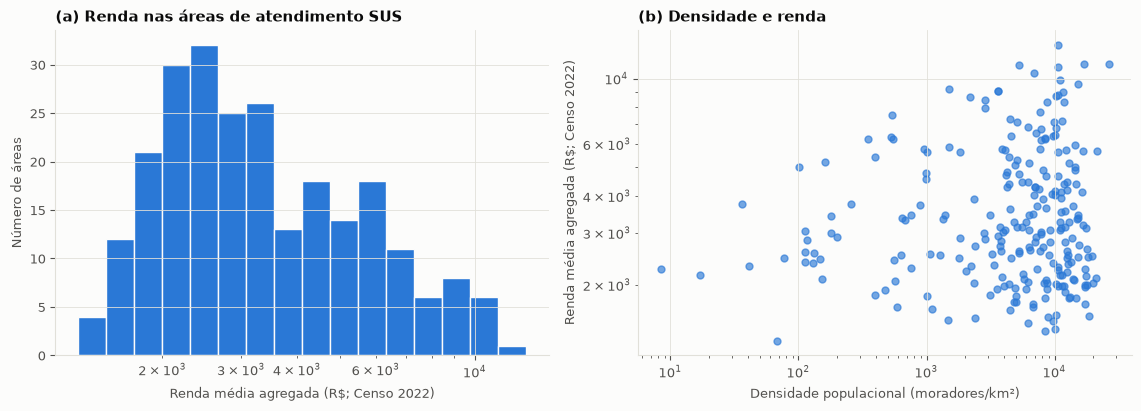

In [2]:
principal = areas["SUS"]
fig, eixos = plt.subplots(1, 2, figsize=(11.5, 4.2))
limites = np.logspace(np.log10(principal.renda_media.min()), np.log10(principal.renda_media.max()), 17)
eixos[0].hist(principal.renda_media, bins=limites, color=estilo.AZUL, edgecolor=estilo.SUPERFICIE)
eixos[0].set_xscale("log")
eixos[0].set(xlabel="Renda média agregada (R$; Censo 2022)", ylabel="Número de áreas")
eixos[0].set_title("(a) Renda nas áreas de atendimento SUS")
eixos[1].scatter(principal.rho, principal.renda_media, color=estilo.AZUL, alpha=0.65, s=25)
eixos[1].set_xscale("log")
eixos[1].set_yscale("log")
eixos[1].set(xlabel="Densidade populacional (moradores/km²)",
              ylabel="Renda média agregada (R$; Censo 2022)")
eixos[1].set_title("(b) Densidade e renda")
fig.tight_layout()
salvar(fig, "01_conhecer_renda")
plt.show()


## 2. Do resíduo da L2 ao modelo com renda

Na L2, o resíduo é:

$$\xi_j=\log_{10}D_j-(\hat c+\hat\alpha\log_{10}\rho_j).$$

Ele compara a oferta observada com a prevista pela densidade. Como usamos logaritmo decimal, $10^{\xi_j}$ é a razão observado/previsto. Por exemplo, um resíduo perto de −0,30 representa aproximadamente metade da densidade de unidades prevista.

A ideia de medir desvios em relação à escala vem dos SAMIs de Bettencourt. **Aqui adaptamos a ideia às áreas de atendimento e à densidade; não estamos usando os SAMIs originais das cidades como uma variável pronta.**

Para estimar o papel da renda, ajustamos **densidade e renda juntas**. Não tratamos uma regressão do resíduo da oferta contra a renda bruta como equivalente: a própria renda também pode se relacionar com a densidade.

**Sinal de δ:**

- δ > 0: renda maior está associada a maior densidade de unidades, considerando a densidade populacional.
- δ < 0: entre as áreas comparadas, renda maior está associada a menor densidade de unidades, mantendo a densidade populacional constante no modelo. Isso pode ser descrito como maior oferta relativa em áreas de menor renda; não significa que a renda cause essa diferença.
- IC incluindo zero: não há evidência de associação diferente de zero segundo este procedimento; isso não comprova ausência de desigualdade.

O α deste modelo é estimado novamente junto com δ. Ele não precisa coincidir com o α da L2 sem renda.


In [3]:
def ajustar(dados):
    X = np.column_stack([np.ones(len(dados)), dados.log10_rho, dados.log10_renda])
    y = dados.log10_D.to_numpy()
    coef, _, posto, _ = np.linalg.lstsq(X, y, rcond=None)
    assert posto == 3, "Variáveis sem variação independente suficiente: investigar."
    previsao = X @ coef
    soma_quadrados = np.sum((y-y.mean())**2)
    return coef, previsao, 1-np.sum((y-previsao)**2)/soma_quadrados

resultados, bootstraps = [], {}
for versao, dados in areas.items():
    coef, previsao, r2 = ajustar(dados)
    rng = np.random.default_rng(SEMENTE)
    sorteios = []
    for _ in range(N_BOOT):
        indices = rng.integers(0, len(dados), len(dados))
        sorteados = dados.iloc[indices]
        coef_boot, _, _ = ajustar(sorteados)
        sorteios.append(coef_boot)
    boot = pd.DataFrame(sorteios, columns=["c", "alpha", "delta"])
    bootstraps[versao] = boot
    ic_alpha = np.percentile(boot.alpha, [2.5, 97.5])
    ic_delta = np.percentile(boot.delta, [2.5, 97.5])
    resultados.append({
        "versao": versao, "n_areas": len(dados), "n_estabelecimentos": int(dados.n_unidades.sum()),
        "n_capitais": dados.capital.nunique(), "c": coef[0], "alpha": coef[1], "delta": coef[2],
        "alpha_ic95_inferior": ic_alpha[0], "alpha_ic95_superior": ic_alpha[1],
        "delta_ic95_inferior": ic_delta[0], "delta_ic95_superior": ic_delta[1],
        "fator_D_renda_dobra": 2**coef[2],
        "fator_ic95_inferior": 2**ic_delta[0], "fator_ic95_superior": 2**ic_delta[1],
        "R2_loglog": r2, "n_bootstrap": len(boot), "semente": SEMENTE,
        "efeitos_fixos_capital": False,
    })
    dados["log10_D_ajustado_com_renda"] = previsao
    dados["residuo_modelo_com_renda"] = dados.log10_D - previsao

    # Retirar a densidade de ambos os eixos permite visualizar exatamente δ.
    X_densidade = np.column_stack([np.ones(len(dados)), dados.log10_rho])
    c_renda = np.linalg.lstsq(X_densidade, dados.log10_renda.to_numpy(), rcond=None)[0]
    c_oferta = np.linalg.lstsq(X_densidade, dados.log10_D.to_numpy(), rcond=None)[0]
    dados["renda_ajustada_densidade"] = dados.log10_renda - X_densidade @ c_renda
    dados["oferta_ajustada_densidade"] = dados.log10_D - X_densidade @ c_oferta
    delta_grafico = np.dot(dados.renda_ajustada_densidade, dados.oferta_ajustada_densidade) / np.dot(
        dados.renda_ajustada_densidade, dados.renda_ajustada_densidade
    )
    np.testing.assert_allclose(delta_grafico, coef[2], rtol=1e-10, atol=1e-10)
    np.testing.assert_allclose(dados.oferta_ajustada_densidade, dados.residuo_L2, atol=1e-10)
    np.testing.assert_allclose(dados.residuo_modelo_com_renda.mean(), 0, atol=1e-10)
    dados.to_csv(SAIDA / f"areas_{versao.lower()}.csv", index=False)
    boot.to_csv(SAIDA / f"bootstrap_{versao.lower()}.csv", index=False)

resultados = pd.DataFrame(resultados)
resultados.to_csv(SAIDA / "resultados_renda.csv", index=False)
display(resultados.set_index("versao")[[
    "n_areas", "alpha", "delta", "delta_ic95_inferior", "delta_ic95_superior",
    "fator_D_renda_dobra", "R2_loglog"
]].round(4))


,n_areas,alpha,delta,delta_ic95_inferior,delta_ic95_superior,fator_D_renda_dobra,R2_loglog
versao,,,,,,,
SUS,245,0.8677,-0.1958,-0.3527,-0.0290,0.8731,0.8204
Todos,272,0.8978,0.0294,-0.1224,0.1881,1.0206,0.8094


## 3. Um gráfico que mostra o papel da renda após considerar a densidade

Para visualizar a regressão com duas variáveis em um plano:

1. No eixo vertical, mostramos a oferta que ficou acima ou abaixo da previsão pela densidade: o resíduo da L2.
2. No eixo horizontal, mostramos a renda que ficou acima ou abaixo de sua relação com a densidade.
3. A inclinação entre esses dois eixos é **o mesmo δ da regressão conjunta**, como conferimos numericamente na célula anterior.

Esses eixos são desvios em logaritmo; não são renda em reais nem número de unidades. A figura é apenas uma forma de apresentar o modelo aprovado, sem acrescentar outro ajuste substantivo.

No gráfico de intervalos, zero é a referência de ausência de associação da renda no modelo. Os intervalos vêm das 2.000 reamostragens de áreas, com o mesmo peso por área. Não incorporam explicitamente dependência espacial ou entre áreas da mesma capital.


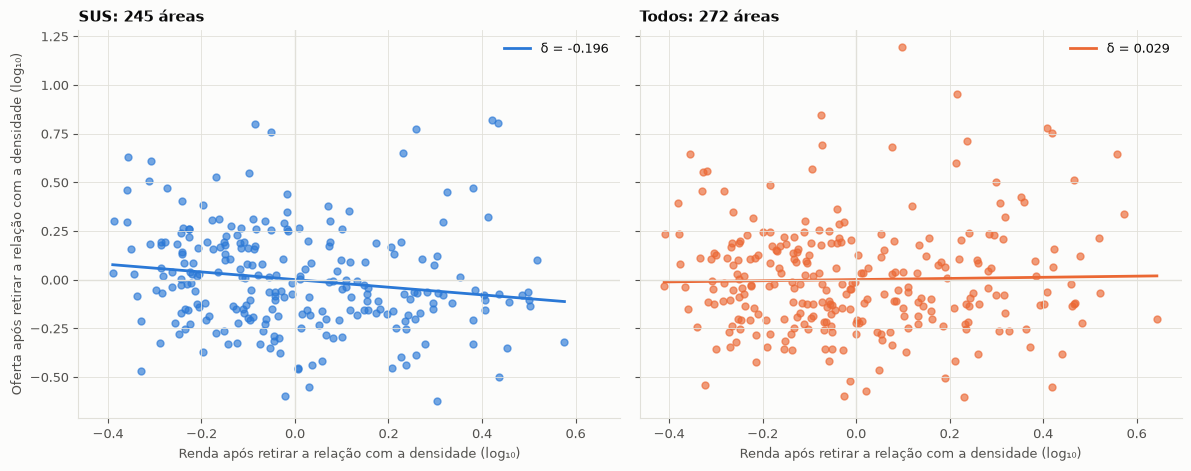

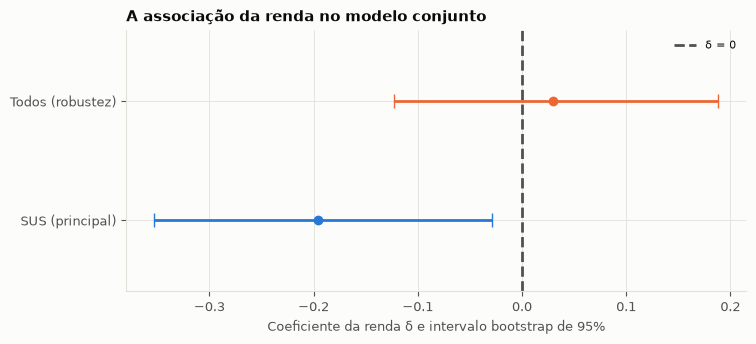

In [4]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True, sharey=True)
for ax, versao, cor in zip(eixos, ["SUS", "Todos"], [estilo.AZUL, estilo.LARANJA]):
    dados = areas[versao]
    resultado = resultados.loc[resultados.versao == versao].iloc[0]
    x = dados.renda_ajustada_densidade
    ax.scatter(x, dados.oferta_ajustada_densidade, s=25, alpha=0.65, color=cor)
    xx = np.linspace(x.min(), x.max(), 100)
    ax.plot(xx, resultado.delta*xx, color=cor, label=f"δ = {resultado.delta:.3f}")
    ax.axhline(0, color=estilo.GRADE, linewidth=1)
    ax.axvline(0, color=estilo.GRADE, linewidth=1)
    ax.set_xlabel("Renda após retirar a relação com a densidade (log₁₀)")
    ax.set_title(f"{versao}: {len(dados)} áreas")
    ax.legend()
eixos[0].set_ylabel("Oferta após retirar a relação com a densidade (log₁₀)")
fig.tight_layout()
salvar(fig, "02_renda_oferta_ajustadas")
plt.show()

fig, ax = plt.subplots(figsize=(8, 3.4))
for i, (versao, cor) in enumerate([("SUS", estilo.AZUL), ("Todos", estilo.LARANJA)]):
    r = resultados.loc[resultados.versao == versao].iloc[0]
    ax.errorbar(r.delta, i, xerr=[[r.delta-r.delta_ic95_inferior], [r.delta_ic95_superior-r.delta]],
                fmt="o", color=cor, capsize=5)
ax.axvline(0, color=estilo.TEXTO_2, linestyle="--", label="δ = 0")
ax.set_yticks([0, 1], ["SUS (principal)", "Todos (robustez)"])
ax.set_ylim(-0.6, 1.6)
ax.set_xlabel("Coeficiente da renda δ e intervalo bootstrap de 95%")
ax.set_title("A associação da renda no modelo conjunto")
ax.legend(fontsize=8)
salvar(fig, "03_intervalos_delta")
plt.show()


## 4. Resultado e interpretação para o artigo

O texto abaixo depende do sinal e do intervalo observados. A transformação $2^\delta$ facilita a leitura: compara a oferta prevista entre áreas cuja renda difere por um fator 2, mantendo a densidade populacional constante no modelo.

Essa comparação não descreve uma mudança causal ao longo do tempo e não mede diretamente a distância percorrida por cada morador.


In [5]:
interpretacoes = []
for _, r in resultados.iterrows():
    if r.delta_ic95_inferior > 0:
        leitura = (
            "O intervalo é positivo: renda maior está associada a maior densidade de "
            "pronto-atendimentos, considerando a densidade populacional neste modelo conjunto."
        )
    elif r.delta_ic95_superior < 0:
        leitura = (
            "O intervalo é negativo: renda maior está associada a menor densidade de "
            "pronto-atendimentos, considerando a densidade populacional. "
            "Em termos simples, neste conjunto de áreas, a oferta prevista é relativamente maior nas de menor renda, mantendo a densidade populacional constante. Isso não demonstra que renda cause a diferença."
        )
    else:
        leitura = (
            "O intervalo inclui zero: não há evidência de associação diferente de zero "
            "segundo este modelo e seu bootstrap. Isso não comprova ausência de desigualdade."
        )
    interpretacoes.append(
        f'**{r.versao}: δ = {r.delta:.3f}, IC 95% '
        f'[{r.delta_ic95_inferior:.3f}; {r.delta_ic95_superior:.3f}].** '
        f'{leitura} A renda duas vezes maior corresponde a multiplicar a oferta prevista '
        f'por **{r.fator_D_renda_dobra:.2f}** '
        f'(IC do fator: {r.fator_ic95_inferior:.2f}–{r.fator_ic95_superior:.2f}).'
    )
interpretacoes.append(
    "**Limite essencial:** o modelo reúne diferenças dentro e entre capitais. "
    "Não podemos atribuir o coeficiente exclusivamente a diferenças entre bairros "
    "da mesma cidade nem concluir causalidade."
)
texto = "\n\n".join(interpretacoes)
display(Markdown(texto))
(SAIDA / "interpretacao_renda.md").write_text(texto+"\n", encoding="utf-8")


**SUS: δ = -0.196, IC 95% [-0.353; -0.029].** O intervalo é negativo: renda maior está associada a menor densidade de pronto-atendimentos, considerando a densidade populacional. Em termos simples, neste conjunto de áreas, a oferta prevista é relativamente maior nas de menor renda, mantendo a densidade populacional constante. Isso não demonstra que renda cause a diferença. A renda duas vezes maior corresponde a multiplicar a oferta prevista por **0.87** (IC do fator: 0.78–0.98).

**Todos: δ = 0.029, IC 95% [-0.122; 0.188].** O intervalo inclui zero: não há evidência de associação diferente de zero segundo este modelo e seu bootstrap. Isso não comprova ausência de desigualdade. A renda duas vezes maior corresponde a multiplicar a oferta prevista por **1.02** (IC do fator: 0.92–1.14).

**Limite essencial:** o modelo reúne diferenças dentro e entre capitais. Não podemos atribuir o coeficiente exclusivamente a diferenças entre bairros da mesma cidade nem concluir causalidade.

986

## 5. O que levar para as três páginas

A análise tem **um único modelo**, repetido como principal (SUS) e robustez (todos). No artigo bastam a equação, δ com intervalo, sua interpretação e a limitação sobre as capitais. Os gráficos e as conferências detalhadas permanecem aqui para estudo e apresentação.

O resultado de renda nas áreas não substitui a tabela densidade × renda por setor nem as distribuições de distância. Cada uma responde a uma parte da pergunta de acesso.

### Limitações desta etapa

- O modelo mistura associações dentro e entre capitais; não controla diferenças específicas de cada capital.
- Densidade populacional e de estabelecimentos compartilham a área no denominador.
- A renda é um indicador agregado do responsável, ponderado pela população; a cobertura de renda varia e não mede necessidade clínica ou acesso a plano de saúde.
- Os estabelecimentos são contados sem capacidade; o grupo compartilhado conta dois estabelecimentos, não o dobro de capacidade comprovada.
- A associação não implica causalidade nem mede diretamente distância ou tempo de viagem.
- O bootstrap de áreas não representa explicitamente dependência entre áreas da mesma cidade ou dependência espacial.

### Fontes já presentes no projeto

- [PLANO.md](../PLANO.md), seção 7.2, e [planejamento.md](../planejamento.md), seção 6.2: modelo conjunto proposto e discussão dos resíduos.
- Bettencourt, *Introduction to Urban Science*, capítulo 4, pp. 127–143: desvios em relação à escala e SAMIs. Adaptamos a ideia; os efeitos fixos não foram usados.
- Gastner e Newman (2006), *Optimal design of spatial distribution networks*: relação de densidades e cuidado com a área compartilhada no denominador.
- Melo et al. (2014), *Statistical Signs of Social Influence on Suicides*: OLS e intervalos bootstrap no contexto de leis de escala. Nosso procedimento reamostra diretamente áreas e não usa a suavização do artigo.

Os PDFs estão em `Bibliografia/`. Não adicionamos referências externas. Todos os resultados desta etapa ficam em `dados/processados/analises/renda/` e os três gráficos, em PNG e PDF, em `figuras/renda/`.
